In [1]:
import kagglehub
import os

path = kagglehub.dataset_download("shree1992/housedata")
print("Path to dataset files:", path)
for root, _, fnames in os.walk(path):
    for f in fnames:
        print(" -", os.path.join(root, f))

Using Colab cache for faster access to the 'housedata' dataset.
Path to dataset files: /kaggle/input/housedata
 - /kaggle/input/housedata/output.csv
 - /kaggle/input/housedata/data.csv
 - /kaggle/input/housedata/data.dat


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
# find the main data file (the one that has the 'price' and 'sqft_living' columns)
csv_file = None
for root, _, fnames in os.walk(path):
    for f in fnames:
        if f.lower().endswith(".csv"):
            cols = pd.read_csv(os.path.join(root, f), nrows=1).columns.str.lower()
            if "price" in cols and "sqft_living" in cols:
                csv_file = os.path.join(root, f)
                break
    if csv_file:
        break
print("Using file:", csv_file)

raw = pd.read_csv(csv_file)
raw.columns = [c.strip().lower() for c in raw.columns]
print("Original size:", raw.shape)

FEATURES = ["sqft_living", "bedrooms", "bathrooms", "floors", "condition"]
TARGET = "price"

df = raw[FEATURES + [TARGET]].dropna()
df = df[df["price"] > 0]                       # this dataset has a few rows with price = 0 (invalid), remove them
N_ROWS = 100                                   # small dataset
df = df.sample(n=N_ROWS, random_state=42).reset_index(drop=True)
df["sqft_living"] = df["sqft_living"] / 1000.0  # in thousands of sq ft (smaller numbers)
df["price"] = df["price"] / 100_000             # in units of $100,000 (smaller numbers)

print("Dataset used:", df.shape)
display(df.head(10))
display(df.describe().round(2))
print("Missing values:", df.isnull().sum().sum())

Using file: /kaggle/input/housedata/output.csv
Original size: (4600, 18)
Dataset used: (100, 6)


,sqft_living,bedrooms,bathrooms,floors,condition,price
0,5.42,4.0,4.50,1.0,3,12.25000
1,1.98,2.0,1.00,1.0,4,4.96752
2,2.73,4.0,2.50,2.0,3,6.12500
3,1.02,3.0,1.00,1.0,5,2.65000
4,2.30,4.0,1.75,1.0,4,6.15000
5,1.97,3.0,2.50,2.0,4,4.32000
6,1.90,6.0,2.00,1.0,2,3.05000
7,1.33,3.0,1.00,1.0,3,4.05000
8,1.43,3.0,2.50,3.0,3,3.49000
9,3.20,3.0,2.50,1.0,3,8.39000


,sqft_living,bedrooms,bathrooms,floors,condition,price
count,100.00,100.00,100.00,100.00,100.00,100.00
mean,2.21,3.52,2.24,1.54,3.45,5.36
std,0.88,0.88,0.81,0.55,0.70,2.82
min,0.74,2.00,1.00,1.00,2.00,1.83
25%,1.64,3.00,1.75,1.00,3.00,3.38
50%,2.18,3.00,2.50,1.50,3.00,4.85
75%,2.71,4.00,2.50,2.00,4.00,6.77
max,5.42,7.00,5.75,3.00,5.00,16.90


Missing values: 0


In [4]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

Train: (80, 5)  Test: (20, 5)


In [5]:
models = {
    "Linear Regression": (LinearRegression(), True),
    "Decision Tree": (DecisionTreeRegressor(max_depth=4, random_state=42), False),
    "Random Forest": (RandomForestRegressor(n_estimators=100, random_state=42), False),
    "Neural Network": (MLPRegressor(hidden_layer_sizes=(16,), max_iter=5000, random_state=42), True),
    "XGBoost": (XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42), False),
    "KNN": (KNeighborsRegressor(n_neighbors=5), True),
}

results, predictions = [], {}
for name, (model, scaled) in models.items():
    Xtr, Xte = (X_train_sc, X_test_sc) if scaled else (X_train, X_test)
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    predictions[name] = pred
    mse = mean_squared_error(y_test, pred)
    results.append({"Model": name, "MAE": mean_absolute_error(y_test, pred),
                    "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_test, pred)})

results_df = pd.DataFrame(results).set_index("Model").round(3).sort_values("R2", ascending=False)
display(results_df)
print("Best model:", results_df["R2"].idxmax())

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5000) reached and the optimization hasn't converged yet.
  warnings.warn(


,MAE,MSE,RMSE,R2
Model,,,,
Linear Regression,1.491,3.423,1.850,0.679
Neural Network,1.522,3.608,1.899,0.662
Decision Tree,1.732,4.934,2.221,0.538
Random Forest,1.721,5.404,2.325,0.494
KNN,1.961,5.637,2.374,0.472
XGBoost,1.741,6.184,2.487,0.421


Best model: Linear Regression


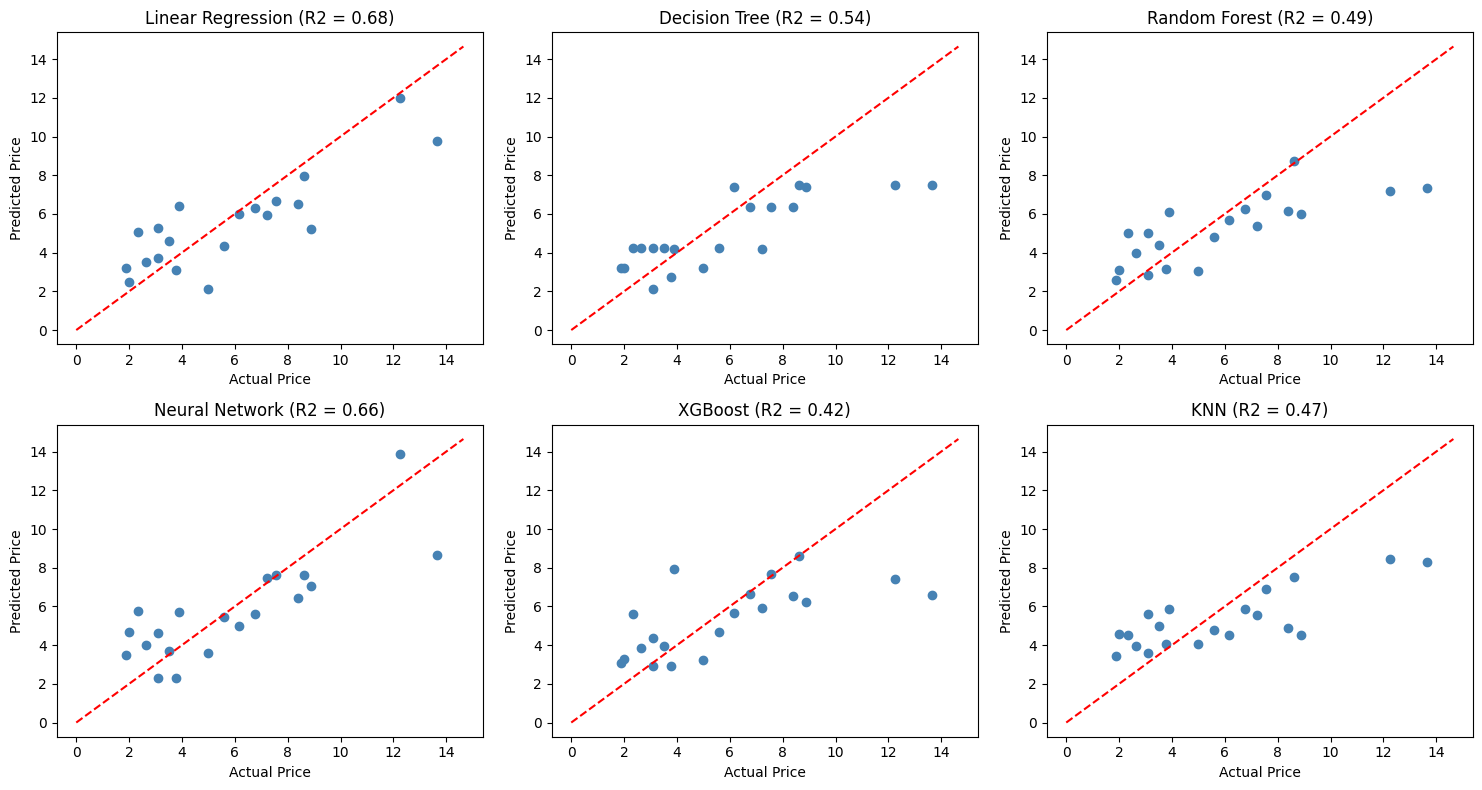

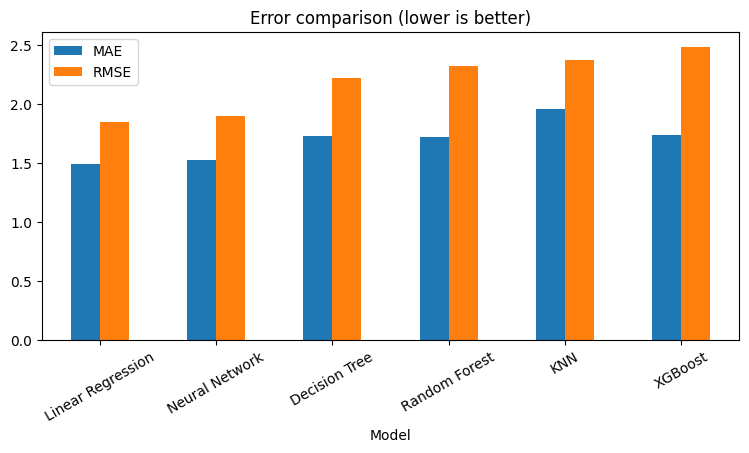

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
lims = [min(y_test.min(), 0), y_test.max() + 1]
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(y_test, pred, color="steelblue")
    ax.plot(lims, lims, "r--")
    ax.set_title(f"{name} (R2 = {r2_score(y_test, pred):.2f})")
    ax.set_xlabel("Actual Price"); ax.set_ylabel("Predicted Price")
plt.tight_layout(); plt.show()

results_df[["MAE", "RMSE"]].plot(kind="bar", figsize=(9, 4), title="Error comparison (lower is better)")
plt.xticks(rotation=30); plt.show()

In [7]:
s = df[["sqft_living", "price"]].head(6).round(2).reset_index(drop=True)
display(s)
x_tr = s["sqft_living"].values[:5]; y_tr = s["price"].values[:5].astype(float)
x_q = float(s["sqft_living"].values[5]); y_q = float(s["price"].values[5])

,sqft_living,price
0,5.42,12.25
1,1.98,4.97
2,2.73,6.12
3,1.02,2.65
4,2.30,6.15
5,1.97,4.32


In [8]:
# Linear Regression
xm, ym = x_tr.mean(), y_tr.mean()
b1 = np.sum((x_tr - xm) * (y_tr - ym)) / np.sum((x_tr - xm) ** 2)
b0 = ym - b1 * xm
print("x_mean", xm, "y_mean", ym, "b1", b1, "b0", b0)
print("LR prediction:", b0 + b1 * x_q, "Actual:", y_q)

# KNN (k=3)
d = np.abs(x_tr - x_q); idx = np.argsort(d)[:3]
print("Distances:", d, "Nearest rows:", idx + 1, "Prices:", y_tr[idx])
print("KNN prediction:", y_tr[idx].mean())

x_mean 2.69 y_mean 6.428 b1 2.1408675547726523 b0 0.6690662776615657
LR prediction: 4.886575360563691 Actual: 4.32
Distances: [3.45 0.01 0.76 0.95 0.33] Nearest rows: [2 5 3] Prices: [4.97 6.15 6.12]
KNN prediction: 5.746666666666667


In [9]:
def sse(v): return float(np.sum((v - v.mean()) ** 2)) if len(v) else 0.0

def best_split(x, y, show=False):
    xs = np.unique(x); best = None
    for t in (xs[:-1] + xs[1:]) / 2:
        L, R = y[x <= t], y[x > t]; tot = sse(L) + sse(R)
        if show: print(f"split<={t:.3f}: SSE_L={sse(L):.3f} SSE_R={sse(R):.3f} total={tot:.3f}")
        if best is None or tot < best[1]: best = (t, tot, L.mean(), R.mean())
    return best

# Decision Tree
t, _, mL, mR = best_split(x_tr, y_tr, show=True)
print("Best split:", t, "Left avg:", mL, "Right avg:", mR)
print("Tree prediction:", mL if x_q <= t else mR)

# Random Forest (3 trees on bootstrap samples)
preds = []
for idx in [[0,1,1,3,4], [0,2,3,3,4], [1,2,2,4,4]]:
    b = best_split(x_tr[idx], y_tr[idx])
    p = y_tr[idx].mean() if b is None else (b[2] if x_q <= b[0] else b[3])
    print("Tree rows", [i+1 for i in idx], "->", p); preds.append(p)
print("Forest prediction:", np.mean(preds))

# XGBoost (one boosting step)
lr = 0.5; base = y_tr.mean(); res = y_tr - base
print("Base:", base, "Residuals:", res)
t, _, rL, rR = best_split(x_tr, res)
r = rL if x_q <= t else rR
print("XGB prediction:", base + lr * r)

split<=1.500: SSE_L=0.000 SSE_R=32.625 total=32.625
split<=2.140: SSE_L=2.691 SSE_R=24.929 total=27.620
split<=2.515: SSE_L=6.342 SSE_R=18.788 total=25.130
split<=4.075: SSE_L=8.097 SSE_R=0.000 total=8.097
Best split: 4.075 Left avg: 4.9725 Right avg: 12.25
Tree prediction: 4.9725
Tree rows [1, 2, 2, 4, 5] -> 4.6850000000000005
Tree rows [1, 3, 4, 4, 5] -> 4.3925
Tree rows [2, 3, 3, 5, 5] -> 4.97
Forest prediction: 4.6825
Base: 6.428 Residuals: [ 5.822 -1.458 -0.308 -3.778 -0.278]
XGB prediction: 5.70025


In [10]:
w, b = np.array([0.5, 0.2]), np.array([0.5, 1.0])
v, c = np.array([0.6, 0.4]), 1.0
z = w * x_q + b
h = np.maximum(0, z)
out = np.dot(v, h) + c
print("z:", z, "h:", h, "Output:", out, "Actual:", y_q)

z: [1.485 1.394] h: [1.485 1.394] Output: 2.4486 Actual: 4.32
